# TP4 – Classificação de Intenções e Agente de IA

## Exercício 1 – Treinamento do classificador de intenções

Neste exercício, vamos dar continuidade ao trabalho desenvolvido
no TP3, utilizando o dataset Customer Support Ticket Dataset.

O objetivo é treinar um classificador de intenções utilizando
TF-IDF e LogisticRegression, avaliar seu desempenho e comparar
os resultados com uma baseline simples.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

dados = pd.read_csv("../data/customer_support_tickets.csv")

print("Dimensões do dataset:", dados.shape)

display(dados[["Ticket Description", "Ticket Type"]].head())

print("\nDistribuição das classes:")
print(dados["Ticket Type"].value_counts())

Dimensões do dataset: (8469, 17)


,Ticket Description,Ticket Type
0,I'm having an issue with the {product_purchase...,Technical issue
1,I'm having an issue with the {product_purchase...,Technical issue
2,I'm facing a problem with my {product_purchase...,Technical issue
3,I'm having an issue with the {product_purchase...,Billing inquiry
4,I'm having an issue with the {product_purchase...,Billing inquiry



Distribuição das classes:
Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64


### 1.1 – Preparação dos dados

Nesta etapa, selecionamos as colunas necessárias para a
classificação, verificamos valores ausentes e dividimos
o dataset em 80% para treinamento e 20% para teste.

Utilizamos uma divisão estratificada para manter a
proporção das classes nos dois conjuntos.

In [2]:
from sklearn.model_selection import train_test_split

dados_ml = dados[["Ticket Description", "Ticket Type"]].copy()

print("Valores ausentes:")
print(dados_ml.isnull().sum())

dados_ml = dados_ml.dropna()

X = dados_ml["Ticket Description"]
y = dados_ml["Ticket Type"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nRegistros para treinamento:", len(X_treino))
print("Registros para teste:", len(X_teste))

print("\nDistribuição das classes no treinamento:")
print(y_treino.value_counts())

Valores ausentes:
Ticket Description    0
Ticket Type           0
dtype: int64

Registros para treinamento: 6775
Registros para teste: 1694

Distribuição das classes no treinamento:
Ticket Type
Refund request          1401
Technical issue         1398
Cancellation request    1356
Product inquiry         1313
Billing inquiry         1307
Name: count, dtype: int64


### 1.2 – Treinamento do classificador

Utilizamos um Pipeline do Scikit-learn composto por
TfidfVectorizer e LogisticRegression.

O TF-IDF transforma os textos em representações numéricas,
enquanto a Regressão Logística realiza a classificação
das intenções dos clientes.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classificador", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

pipeline.fit(X_treino, y_treino)

y_pred = pipeline.predict(X_teste)
y_prob = pipeline.predict_proba(X_teste)

print("Modelo treinado com sucesso!")
print("Classes:", pipeline.classes_)

Modelo treinado com sucesso!
Classes: ['Billing inquiry' 'Cancellation request' 'Product inquiry'
 'Refund request' 'Technical issue']


### 1.3 – Avaliação do desempenho do classificador

Após o treinamento, avaliamos o desempenho do modelo
utilizando os dados de teste.

As métricas utilizadas foram acurácia, precision, recall,
F1-score por classe e ROC-AUC multiclasse, permitindo
identificar a capacidade do modelo de distinguir as
diferentes intenções dos clientes.

In [4]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score
)

acuracia = accuracy_score(y_teste, y_pred)

f1_macro = f1_score(
    y_teste, y_pred, average="macro"
)

roc_auc = roc_auc_score(
    y_teste,
    y_prob,
    multi_class="ovr",
    average="macro",
    labels=pipeline.classes_
)

print(f"Acurácia: {acuracia:.4f}")
print(f"F1-score Macro: {f1_macro:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

print("\nRelatório de classificação:\n")

print(classification_report(
    y_teste,
    y_pred,
    zero_division=0
))

Acurácia: 0.1948
F1-score Macro: 0.1944
ROC-AUC: 0.4937

Relatório de classificação:

                      precision    recall  f1-score   support

     Billing inquiry       0.17      0.17      0.17       327
Cancellation request       0.19      0.18      0.18       339
     Product inquiry       0.21      0.22      0.21       328
      Refund request       0.20      0.21      0.21       351
     Technical issue       0.19      0.20      0.20       349

            accuracy                           0.19      1694
           macro avg       0.19      0.19      0.19      1694
        weighted avg       0.19      0.19      0.19      1694



### 1.4 – Matriz de confusão

A matriz de confusão permite visualizar os acertos
e erros do classificador, identificando quais intenções
são confundidas com maior frequência pelo modelo.

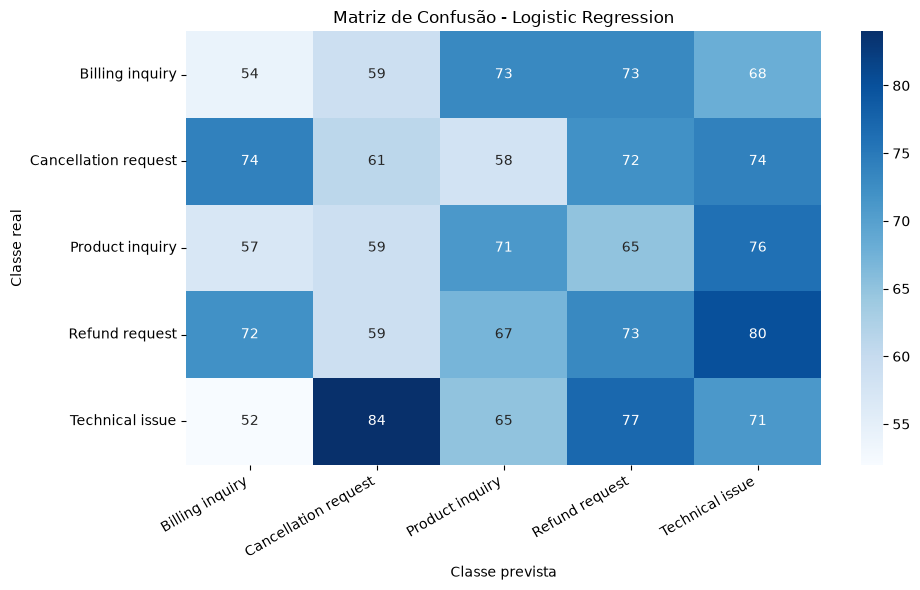

In [5]:
from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(
    y_teste,
    y_pred,
    labels=pipeline.classes_
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=pipeline.classes_,
    yticklabels=pipeline.classes_
)

plt.title("Matriz de Confusão - Logistic Regression")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 1.5 – Comparação com a baseline

Para avaliar o desempenho do classificador, utilizamos
uma baseline simples com o DummyClassifier, que prevê
sempre a classe mais frequente do conjunto de treinamento.

A comparação permite verificar se o modelo treinado
apresenta vantagens em relação a uma estratégia simples
de classificação.

In [6]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_treino, y_treino)

y_pred_baseline = baseline.predict(X_teste)
y_prob_baseline = baseline.predict_proba(X_teste)

resultados = pd.DataFrame({
    "Modelo": ["Baseline", "TF-IDF + LogisticRegression"],
    "Acurácia": [
        accuracy_score(y_teste, y_pred_baseline),
        acuracia
    ],
    "F1-score Macro": [
        f1_score(y_teste, y_pred_baseline, average="macro"),
        f1_macro
    ],
    "ROC-AUC": [
        roc_auc_score(
            y_teste,
            y_prob_baseline,
            multi_class="ovr",
            average="macro",
            labels=baseline.classes_
        ),
        roc_auc
    ]
})

display(resultados.round(4))

,Modelo,Acurácia,F1-score Macro,ROC-AUC
0,Baseline,0.2072,0.0687,0.5000
1,TF-IDF + LogisticRegression,0.1948,0.1944,0.4937


### 1.6 – Análise dos resultados e conclusão

O classificador foi treinado utilizando o pipeline
TF-IDF + LogisticRegression, com 6.775 registros para
treinamento e 1.694 registros para teste.
Os resultados obtidos foram:

| Métrica | Baseline | LogisticRegression |
|---|---:|---:|
| Acurácia | 20,72% | 19,48% |
| F1-score Macro | 0,0687 | 0,1944 |
| ROC-AUC | 0,5000 | 0,4937 |

Ao analisar os resultados, percebemos que o modelo
apresentou dificuldades para distinguir as cinco
classes de intenção.

Apesar de possuir uma acurácia inferior à baseline,
o classificador apresentou um F1-score Macro superior,
pois conseguiu realizar previsões para todas as classes,
diferentemente da baseline, que sempre prevê a classe
mais frequente.

A matriz de confusão apresentou uma distribuição
considerável de erros entre todas as classes.

Uma possível justificativa para esse desempenho é a
semelhança entre as descrições dos tickets, mesmo
quando pertencem a categorias diferentes.

O ROC-AUC próximo de 0,5 indica que a capacidade de
distinção entre as classes ainda é limitada.

Na próxima etapa de otimização, utilizaremos o
GridSearchCV para verificar se ajustes nos
hiperparâmetros conseguem melhorar o desempenho
do classificador.

## Exercício 2 – Integração do classificador com FastAPI

### 2.1 – Persistência do modelo treinado

Utilizamos a biblioteca Joblib para salvar o pipeline
treinado no exercício anterior, permitindo que a API
realize previsões sem precisar treinar o modelo
novamente a cada solicitação.

In [8]:
import joblib
from pathlib import Path

pasta_modelo = Path("../fastapi/ml")
pasta_modelo.mkdir(parents=True, exist_ok=True)

caminho_modelo = pasta_modelo / "classificador.joblib"

joblib.dump(pipeline, caminho_modelo)

print("Modelo salvo com sucesso!")
print("Local:", caminho_modelo.resolve())

Modelo salvo com sucesso!
Local: /Users/idalioreis/Desktop/junior_matheus_paulo_tp3/fastapi/ml/classificador.joblib


### 2.2 – Implementação do endpoint de classificação

Foi criado o endpoint POST /classify na API FastAPI,
reutilizando a autenticação JWT implementada no TP3.

O endpoint recebe um texto no formato JSON, utiliza
o pipeline treinado e retorna a intenção prevista
e sua respectiva probabilidade.

### 2.3 – Testes e resultados

Foram realizados dois testes utilizando o Swagger:

| Teste | Resultado |
|---|---|
| Requisição sem JWT | 401 Unauthorized |
| Requisição com JWT válido | 200 OK |

No teste autenticado, utilizamos a mensagem:

"I would like to cancel my subscription."

O modelo retornou a intenção Billing inquiry, com
uma probabilidade de aproximadamente 35,36%.

Embora a intenção prevista não corresponda à intenção
esperada, o teste confirmou o funcionamento da
integração entre a API e o modelo treinado.

Esse erro de classificação está relacionado ao baixo
desempenho observado no exercício anterior.

A autenticação JWT também funcionou corretamente,
impedindo o acesso ao endpoint sem autenticação.

## Exercício 3 – Otimização de hiperparâmetros

### 3.1 – Configuração do GridSearchCV

Com o objetivo de melhorar o desempenho do classificador,
utilizamos o GridSearchCV para testar diferentes combinações
de hiperparâmetros do pipeline.

Foram selecionados dois parâmetros, cada um com três
valores diferentes, totalizando nove combinações.

Utilizamos validação cruzada com cinco folds e o
F1-score Macro como métrica de avaliação, considerando
a importância de todas as classes de intenção.

In [10]:
from sklearn.model_selection import GridSearchCV

parametros = {
    "classificador__C": [0.1, 1, 10],
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=parametros,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_treino, y_treino)

print("\nMelhores hiperparâmetros:")
print(grid_search.best_params_)

print("\nMelhor F1-score na validação cruzada:")
print(f"{grid_search.best_score_:.4f}")

Fitting 5 folds for each of 9 candidates, totalling 45 fits

Melhores hiperparâmetros:
{'classificador__C': 1, 'tfidf__ngram_range': (1, 1)}

Melhor F1-score na validação cruzada:
0.1940


### 3.2 – Avaliação do modelo otimizado

Após a busca pelos melhores hiperparâmetros,
avaliamos o modelo otimizado utilizando o mesmo
conjunto de teste do exercício 1.

Dessa forma, conseguimos comparar o desempenho
dos modelos nas mesmas condições.

In [11]:
melhor_modelo = grid_search.best_estimator_

y_pred_otimizado = melhor_modelo.predict(X_teste)
y_prob_otimizado = melhor_modelo.predict_proba(X_teste)

acuracia_otimizada = accuracy_score(
    y_teste, y_pred_otimizado
)

f1_otimizado = f1_score(
    y_teste,
    y_pred_otimizado,
    average="macro"
)

roc_auc_otimizado = roc_auc_score(
    y_teste,
    y_prob_otimizado,
    multi_class="ovr",
    average="macro",
    labels=melhor_modelo.classes_
)

print(f"Acurácia: {acuracia_otimizada:.4f}")
print(f"F1-score Macro: {f1_otimizado:.4f}")
print(f"ROC-AUC: {roc_auc_otimizado:.4f}")

print("\nRelatório de classificação:\n")

print(classification_report(
    y_teste,
    y_pred_otimizado,
    zero_division=0
))

Acurácia: 0.1948
F1-score Macro: 0.1944
ROC-AUC: 0.4937

Relatório de classificação:

                      precision    recall  f1-score   support

     Billing inquiry       0.17      0.17      0.17       327
Cancellation request       0.19      0.18      0.18       339
     Product inquiry       0.21      0.22      0.21       328
      Refund request       0.20      0.21      0.21       351
     Technical issue       0.19      0.20      0.20       349

            accuracy                           0.19      1694
           macro avg       0.19      0.19      0.19      1694
        weighted avg       0.19      0.19      0.19      1694



### 3.3 – Comparação dos resultados e conclusão

O GridSearchCV realizou a busca utilizando dois
hiperparâmetros, com três valores cada, totalizando
nove combinações e 45 avaliações com validação cruzada.

Os melhores hiperparâmetros encontrados foram:

- C: 1
- ngram_range: (1, 1)
- F1-score na validação cruzada: 0,1940

A comparação dos resultados no conjunto de teste
apresentou os seguintes valores:

| Métrica | Original | Otimizado |
|---|---:|---:|
| Acurácia | 19,48% | 19,48% |
| F1-score Macro | 0,1944 | 0,1944 |
| ROC-AUC | 0,4937 | 0,4937 |

Após a execução do GridSearchCV, percebemos que os
melhores hiperparâmetros encontrados correspondem
à configuração original do pipeline.

Portanto, não houve ganho de desempenho com as
combinações testadas.

Uma possível explicação para esse resultado está na
semelhança entre os textos das diferentes classes
do dataset, dificultando a identificação das intenções.

Optamos por manter o modelo original salvo com
Joblib e integrado à API FastAPI.

### 4.4 – Evidência da execução do agente

A imagem abaixo demonstra a execução do agente de
atendimento, incluindo a autenticação JWT, a consulta
ao endpoint de classificação e os três turnos de conversa.

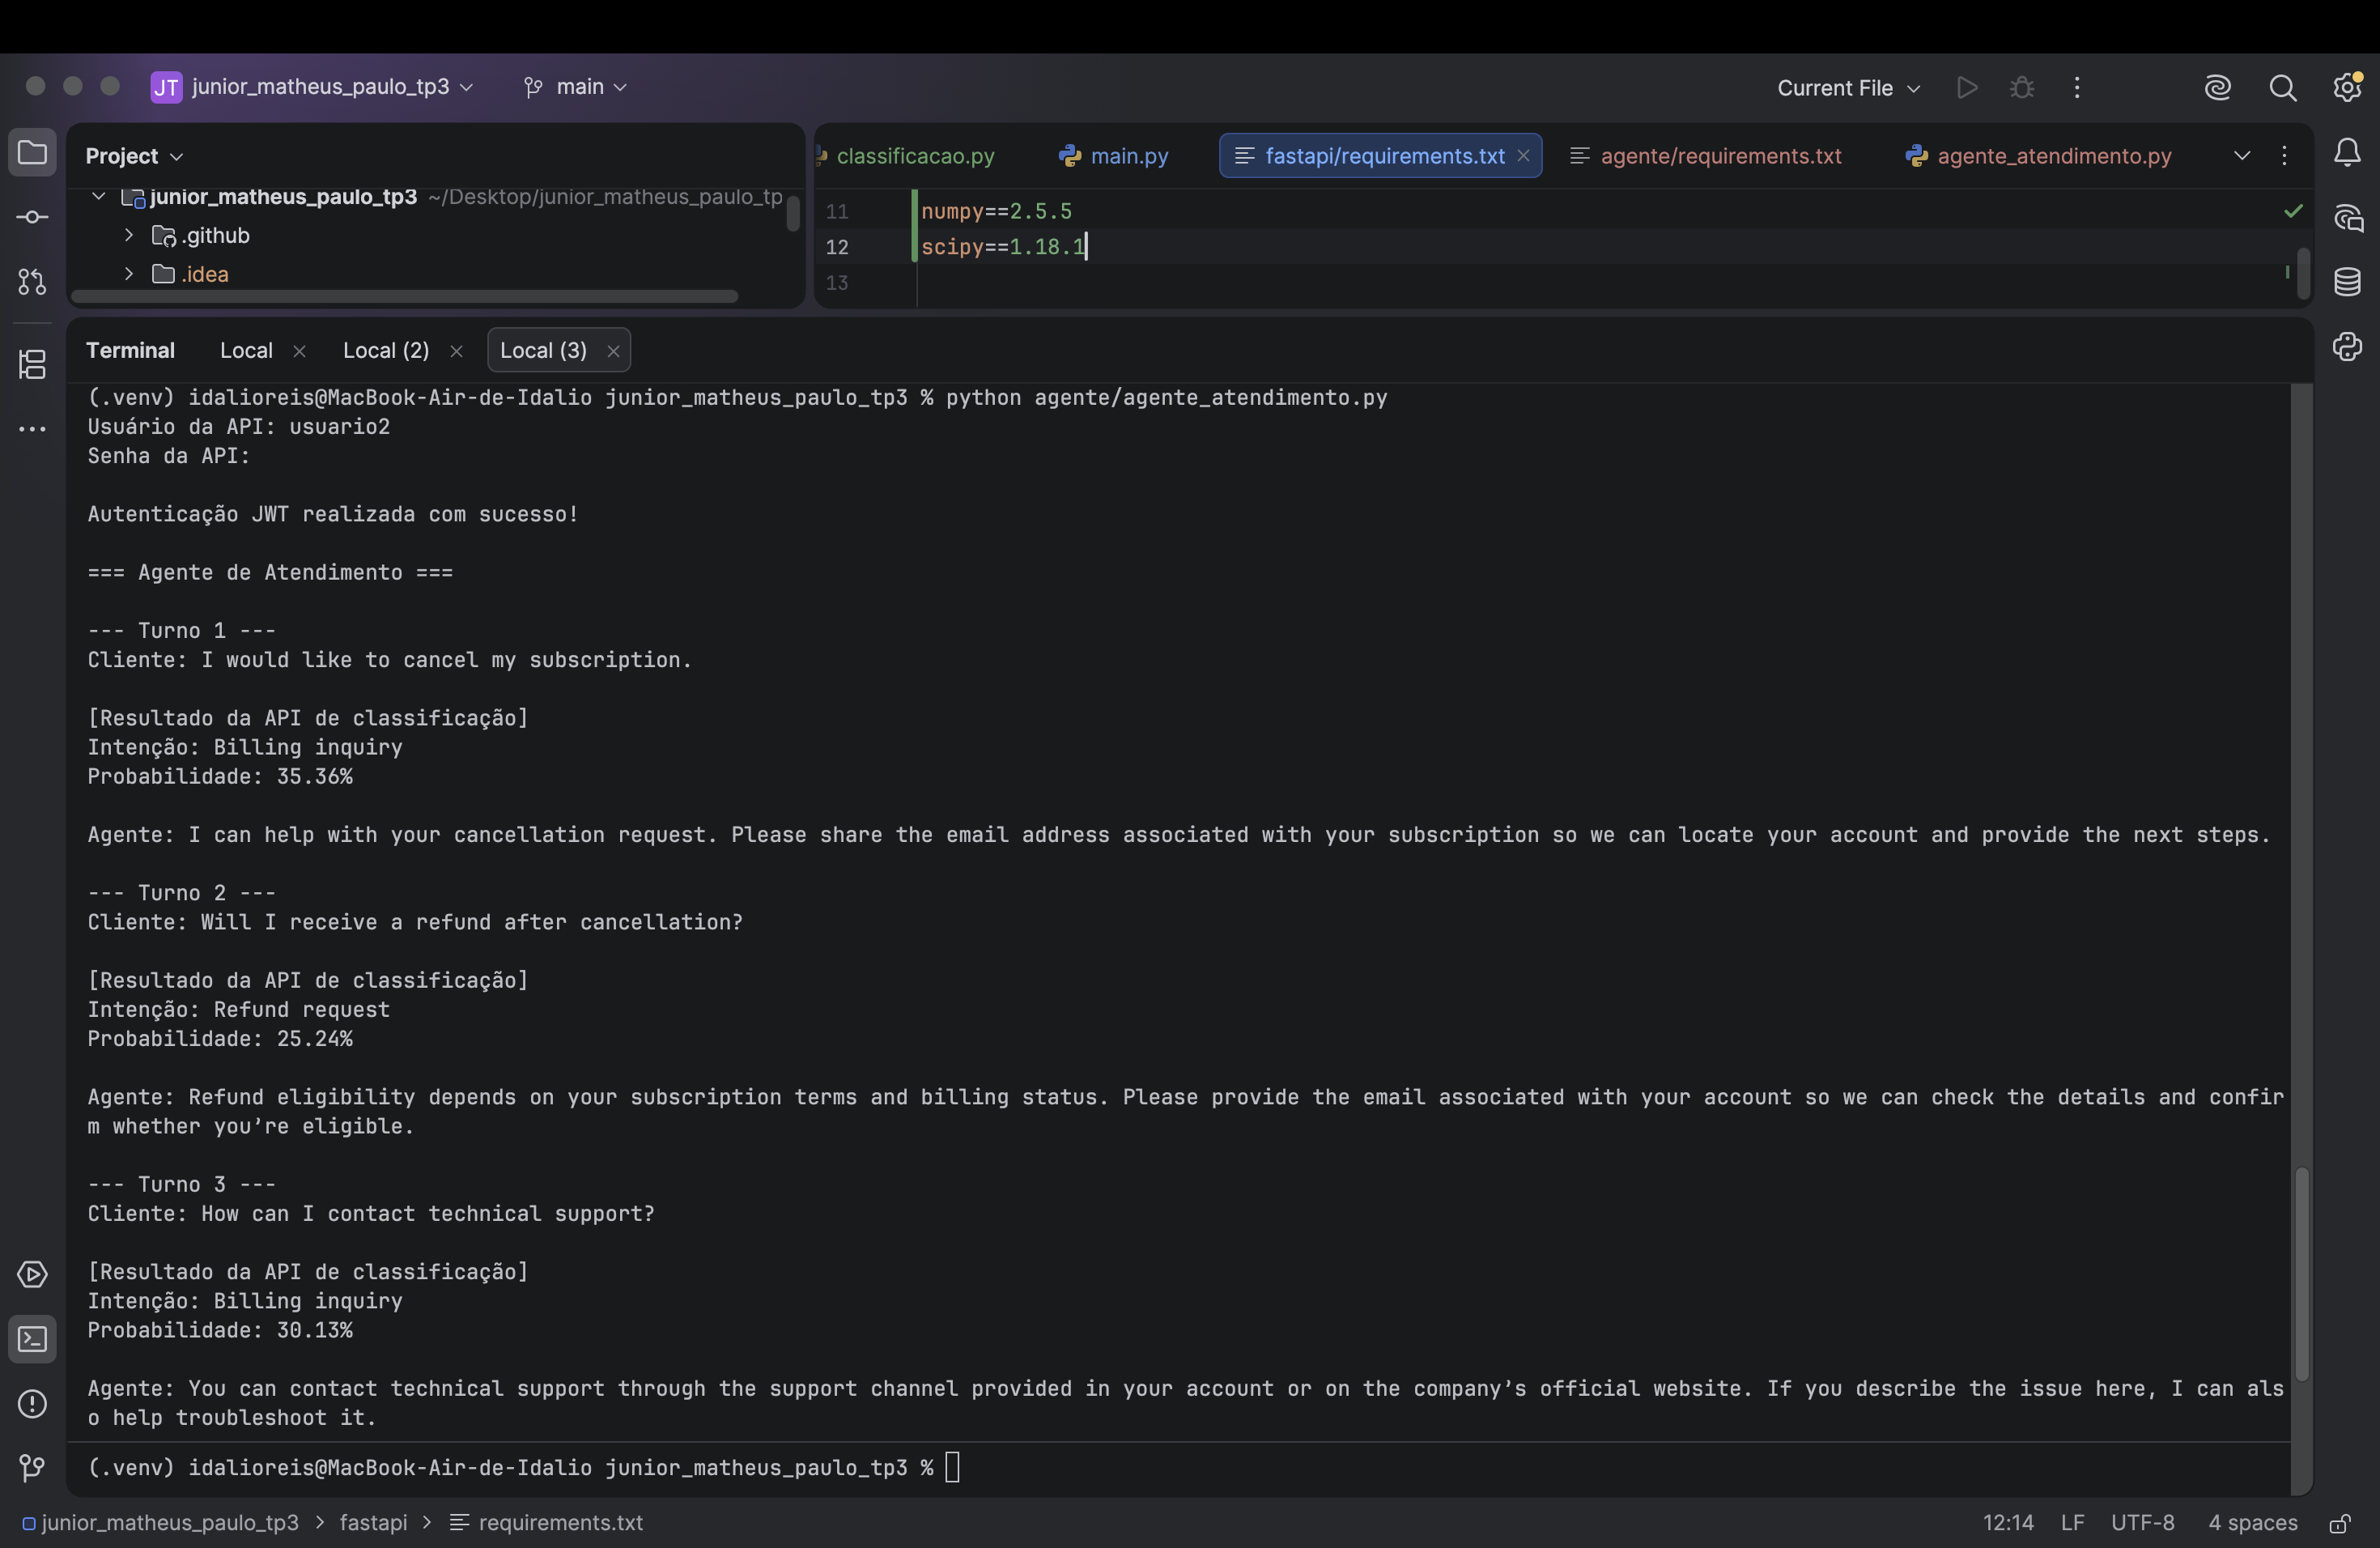